# Computer Vision 2026-2027 - NOVA FCT

## Project Stage 1 - Shot boundary detection and recurring scenes

**Authors**:
- 73213, Tomás Alexandre, tf.alexandre@campus.fct.unl.pt
- 77580, Ana Francisco, am.francisco@campus.fct.unl.pt

## 1. Introduction

Um vídeo editado é uma sequência de *shots* (tomadas contínuas de uma câmara) separados por transições; neste projeto todas as transições são cortes secos. O trabalho tem três partes: (1) detetar os cortes medindo a diferença entre frames consecutivas com três sinais (diferença de píxeis, histogramas de cor e *Edge Change Ratio*); (2) eliminar falsos alarmes, como *flashes* e movimento de câmara, verificando cada candidato com *features* locais (SIFT); e (3) agrupar os *shots* que mostram a mesma cena.

Todos os parâmetros foram escolhidos nos vídeos de desenvolvimento (`dev_01`, `dev_02`); os vídeos de teste só são usados para os resultados finais (secção 5). O código está em `tp1.py` e este notebook importa-o.

## 2. Part 1 - Frame dissimilarity and hard cuts

In [25]:
%load_ext autoreload
%autoreload 2

import os
import json
import glob
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

from tp1 import (
    read_frames,
    compute_pixel_diff_signal,
    compute_histogram_signal,
    compute_ecr_signal,
    detect_cuts,
    detect_cuts_combined,
    compute_edges
)
import plotting
import metrics

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Task 1 - Leitura e redução das frames

Os vídeos têm 640×360 a 25 fps. Lemos todas as frames com `read_frames`, que as reduz para **320×180** (metade em cada dimensão, mantendo a proporção 16:9) com interpolação `INTER_AREA`. Como vimos no Lab 1, o `INTER_AREA` faz a média dos píxeis de cada área, por isso é o método indicado para reduzir imagens: evita *aliasing* e atenua o ruído de compressão.

Justificação da escolha:
- **Tempo**: o Canny, a dilatação e os histogramas são proporcionais ao número de píxeis, que fica 4× menor (ver medição abaixo). O programa tem de correr os 4 vídeos em menos de 5 minutos.
- **Memória**: ≈3 800 frames × 320×180×3 bytes ≈ 0,66 GB por vídeo, contra ≈2,6 GB à resolução original.
- **Informação suficiente**: um corte muda o conteúdo da imagem inteira, o que continua bem visível a 320×180. Os pormenores que se perdem (texturas finas, ruído) só criariam arestas e variações irrelevantes.

In [26]:
video_path = os.path.join("..", "input", "dev_01.mp4")

frames = read_frames(video_path)
total_frames = len(frames)

print(f"Total de frames: {total_frames}")
print(f"Resolução da primeira frame (H, W, C): {frames[0].shape}")

Total de frames: 3809
Resolução da primeira frame (H, W, C): (180, 320, 3)


In [27]:
# Medir o tempo dos sinais (histograma + ECR) em 200 frames, à resolução original e reduzida
cap = cv2.VideoCapture(video_path)
full = []
while len(full) < 200:
    ok, f = cap.read()
    if not ok:
        break
    full.append(f)
cap.release()
small = [cv2.resize(f, (320, 180), interpolation=cv2.INTER_AREA) for f in full]

for label, fr in [("original 640x360", full), ("reduzida 320x180", small)]:
    t0 = time.time()
    compute_histogram_signal(fr)
    compute_ecr_signal(fr)
    print(f"{label}: {1000 * (time.time() - t0) / len(fr):.2f} ms por frame")
del full, small

original 640x360: 2.87 ms por frame
reduzida 320x180: 0.59 ms por frame


In [28]:
input_dir = os.path.join("..", "input")
dev_files = sorted(glob.glob(os.path.join(input_dir, "dev_*.mp4")))

dev_data = {}

for video_path in dev_files:
    name = os.path.splitext(os.path.basename(video_path))[0]
    json_path = os.path.join(input_dir, f"{name}.json")

    with open(json_path, "r") as f:
        gt = json.load(f)

    frames = read_frames(video_path)

    print(f"A calcular sinais para {name} ({len(frames)} frames)...")
    dev_data[name] = {
        "gt": gt,
        "frames": frames,
        "signals": {
            "Pixel Difference": compute_pixel_diff_signal(frames),
            "Histogram Distance (Chi2)": compute_histogram_signal(frames, bins=(8, 8, 8), space="rgb"),
            "ECR": compute_ecr_signal(frames)
        }
    }

print("Cálculo dos sinais concluído para todo o conjunto de desenvolvimento (DEV)!")

A calcular sinais para dev_01 (3809 frames)...
A calcular sinais para dev_02 (3760 frames)...
Cálculo dos sinais concluído para todo o conjunto de desenvolvimento (DEV)!


In [29]:
# Função auxiliar: avalia uma lista de cortes previstos por vídeo em todo o DEV
# (soma TP, FP e FN dos dois vídeos, como o sum_counts)
def evaluate_cuts(pred_per_video):
    total_tp, total_fp, total_fn, total_fa = 0, 0, 0, 0
    for name, data in dev_data.items():
        gt_cuts = [trans["start"] for trans in data["gt"]["transitions"] if trans["type"] == "cut"]
        tp, fp, fn = metrics.match_cuts(gt_cuts, pred_per_video[name])
        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_fa += metrics.flash_false_alarms(data["gt"]["distractors"], pred_per_video[name])
    p, r, f1 = metrics.precision_recall_f1(total_tp, total_fp, total_fn)
    return p, r, f1, total_fa

num_flashes = sum(len(data["gt"]["distractors"]) for data in dev_data.values())

### Task 2 - Três sinais de dissimilaridade

#### A. Pixel Difference (Baseline)
Calcula a média das diferenças absolutas dos níveis de cinzento entre $t-1$ e $t$. É sensível a movimentos globais de câmara e a variações de iluminação.

#### B. Histogram Distance ($\chi^2$)
Comparámos histogramas HSV (só canais $H$ e $S$, que à partida seriam mais robustos a variações de brilho) com histogramas RGB, para vários números de *bins* (tabela abaixo). Ao contrário do esperado, o **RGB com $8 \times 8 \times 8$ bins** teve o melhor $F_1$ no DEV (0.908 contra 0.887 do HSV 16×16). Uma explicação é que, ao ignorar o canal $V$, o HSV deixa de distinguir planos com tons semelhantes mas brilho diferente; a robustez a *flashes* também não se verificou, já que estes geram falsos alarmes com ambos os espaços. Entre 8×8×8 e 16×16×16 o resultado é igual, por isso ficámos com o mais simples. O histograma é calculado com `cv2.calcHist` e a distância Qui-Quadrado ($\chi^2$) normalizada é implementada por nós com NumPy:
$$\chi^2(h_1, h_2) = \frac{1}{2} \sum_{i} \frac{(h_1[i] - h_2[i])^2}{h_1[i] + h_2[i]}$$

#### C. Edge Change Ratio (ECR)
Mede a fração de contornos que entram ($X_t^{in}$) ou saem ($X_t^{out}$) entre $t-1$ e $t$, usando Canny e dilatação ($5 \times 5$) para permitir uma pequena margem de tolerância ao movimento do objeto/câmara.

- **Limiares de Canny**: 100 e 200, valores comuns que ignoram a maior parte do ruído e das texturas fracas.
- **Kernel de dilatação**: $5 \times 5$, como sugerido no enunciado. Com frames de 320×180, cobre deslocamentos de até 2 píxeis entre frames consecutivas.
- **Frames sem arestas**: se uma frame não tem contornos (por exemplo, uma frame preta), a razão correspondente é 0, para nunca dividir por zero.

#### Os três sinais em frames reais
A figura mostra três pares de frames consecutivas de `dev_01`: dentro de um *shot* (frame do meio do *shot* mais longo), num corte (o corte onde a distância de histogramas é menor, ou seja, o mais difícil para as cores) e no início de um *flash*. A última coluna mostra as arestas como na Figura 2 do enunciado: a cinzento as arestas dilatadas de $t-1$, a verde as arestas de $t$ que caem dentro delas e a vermelho as que entram ($X_t^{in}$).

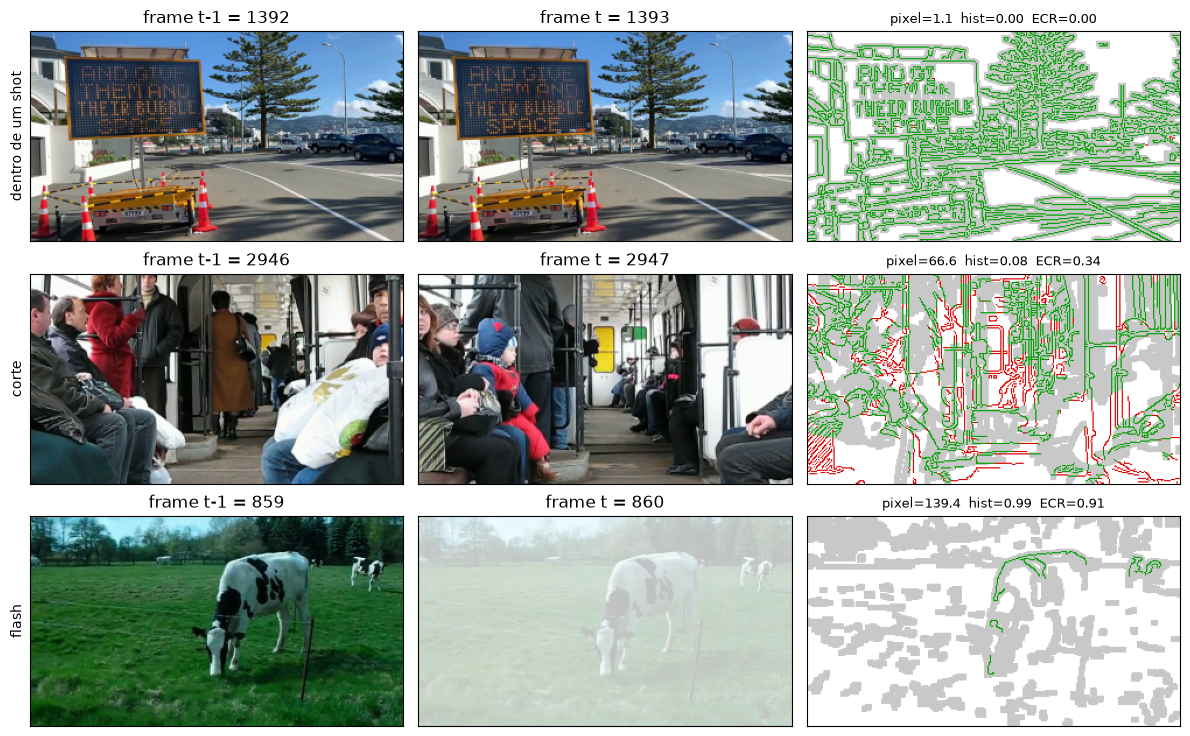

In [30]:
def ecr_overlay(f_prev, f_t):
    # cinzento = arestas dilatadas de t-1; verde = arestas de t perto de t-1; vermelho = arestas que entram
    e_prev, d_prev = compute_edges(f_prev)
    e_t, _ = compute_edges(f_t)
    img = np.full(e_t.shape + (3,), 255, np.uint8)
    img[d_prev] = (200, 200, 200)
    img[e_t & d_prev] = (0, 160, 0)
    img[e_t & ~d_prev] = (220, 0, 0)
    return img

data = dev_data["dev_01"]
sig = data["signals"]
longest = max(data["gt"]["shots"], key=lambda s: s["end"] - s["start"])
cut_frames = [trans["start"] for trans in data["gt"]["transitions"]]

pairs = [("dentro de um shot", (longest["start"] + longest["end"]) // 2),
         ("corte", min(cut_frames, key=lambda t: sig["Histogram Distance (Chi2)"][t])),
         ("flash", data["gt"]["distractors"][0]["start"])]

fig, axs = plt.subplots(3, 3, figsize=(12, 7.5))
for row, (label, t) in enumerate(pairs):
    f_prev, f_t = data["frames"][t - 1], data["frames"][t]
    axs[row][0].imshow(cv2.cvtColor(f_prev, cv2.COLOR_BGR2RGB))
    axs[row][0].set_title(f"frame t-1 = {t - 1}")
    axs[row][1].imshow(cv2.cvtColor(f_t, cv2.COLOR_BGR2RGB))
    axs[row][1].set_title(f"frame t = {t}")
    axs[row][2].imshow(ecr_overlay(f_prev, f_t))
    axs[row][2].set_title(f"pixel={sig['Pixel Difference'][t]:.1f}  hist={sig['Histogram Distance (Chi2)'][t]:.2f}  "
                          f"ECR={sig['ECR'][t]:.2f}", fontsize=9)
    axs[row][0].set_ylabel(label)
    for ax in axs[row]:
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
plt.show()

O par dentro do *shot* tem os três sinais praticamente a zero. O corte mostrado é o mais difícil para o histograma: liga dois *takes* diferentes do mesmo local (o interior de um elétrico), com cores muito parecidas, e por isso a distância χ² é só 0.08. A diferença de píxeis (66.6) e o ECR (0.34, muitas arestas a vermelho) detetam-no claramente, o que motiva a combinação de sinais. O *flash* faz disparar os três sinais com valores tão altos como num corte: a imagem fica quase branca e a maioria das arestas desaparece, por isso nenhum limiar o distingue de um corte verdadeiro.

#### Escolha do espaço de cor e do número de *bins*
Para cada configuração calculamos o sinal de histograma no DEV e guardamos o melhor $F_1$ ao varrer o limiar.

In [31]:
configs = [("hsv", (8, 8)), ("hsv", (16, 16)), ("hsv", (32, 32)), ("rgb", (8, 8, 8)), ("rgb", (16, 16, 16))]

print(f"{'Espaço':<8} | {'Bins':<10} | {'Melhor T':<9} | {'F1':<6}")
print("-" * 42)
for space, bins in configs:
    sigs = {name: compute_histogram_signal(data["frames"], bins=bins, space=space) for name, data in dev_data.items()}
    best_f1, best_t = 0.0, 0.0
    for t in np.linspace(0, 1, 101):
        p, r, f1, _ = evaluate_cuts({name: detect_cuts(sigs[name], t) for name in dev_data})
        if f1 > best_f1:
            best_f1, best_t = f1, t
    print(f"{space:<8} | {'x'.join(map(str, bins)):<10} | {best_t:<9.2f} | {best_f1:<6.3f}")

Espaço   | Bins       | Melhor T  | F1    
------------------------------------------
hsv      | 8x8        | 0.21      | 0.887 
hsv      | 16x16      | 0.24      | 0.887 
hsv      | 32x32      | 0.29      | 0.895 
rgb      | 8x8x8      | 0.11      | 0.908 
rgb      | 16x16x16   | 0.19      | 0.908 


#### Deliverable — Gráfico dos Sinais (~30 Segundos)
Visualização dos três sinais de dissimilaridade em 30 segundos do vídeo `dev_01`, com as linhas verticais dos cortes reais e *flashes* do *ground-truth* sobrepostas. Escolhemos uma janela que começa 10 s antes do primeiro *flash*, para se ver como cada sinal reage a ele.

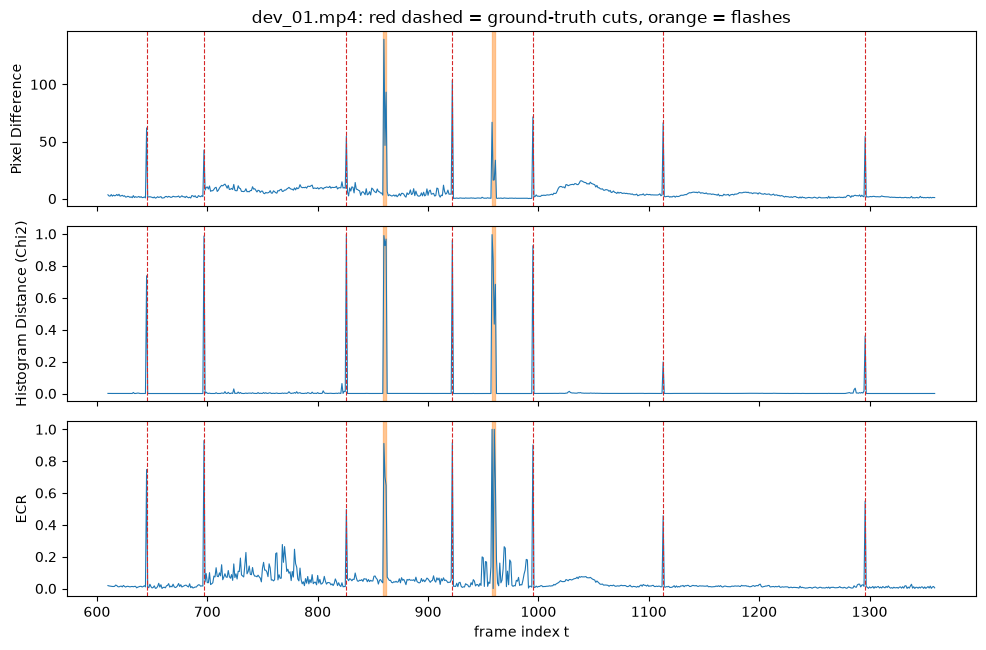

In [32]:
dev01_gt = dev_data["dev_01"]["gt"]
fps = dev01_gt.get("fps", 25)

# 30 segundos a começar 10 s antes do primeiro flash
first_flash = dev01_gt["distractors"][0]["start"] if dev01_gt["distractors"] else 0
start = max(0, first_flash - 10 * fps)

plotting.plot_signals(
    signals=dev_data["dev_01"]["signals"],
    gt=dev01_gt,
    start=start,
    end=start + 30 * fps
)
plt.show()

#### Deliverable — Varrimento de Limiares e Tabela de Comparação
A escolha dos limiares ($T$) é efetuada no conjunto total de desenvolvimento (`DEV` = `dev_01` + `dev_02`). Para cada sinal, varia-se o limiar $T$ ao longo de um intervalo de valores, contabilizando $TP$, $FP$ e $FN$ com a função `metrics.match_cuts`.

Um corte é declarado em $t$ quando $d(t) > T$ e $d(t)$ é o máximo local numa janela de $\pm 5$ frames (`detect_cuts`). Sem esta condição, quando duas frames seguidas passam o limiar no mesmo corte, a segunda conta como falso positivo.

In [33]:
signal_names = ["Pixel Difference", "Histogram Distance (Chi2)", "ECR"]
pr_curves_data = {}
best_results = {}

for s_name in signal_names:
    # Determinar valor máximo do sinal em todo o DEV
    max_val = max(np.max(dev_data[v]["signals"][s_name]) for v in dev_data)
    thresholds = np.linspace(0, max_val, 200)

    points = []
    best_f1, best_p, best_r, best_t = -1.0, 0.0, 0.0, 0.0

    for t in thresholds:
        total_tp, total_fp, total_fn = 0, 0, 0

        for name, data in dev_data.items():
            sig = data["signals"][s_name]
            gt_cuts = [trans["start"] for trans in data["gt"]["transitions"] if trans["type"] == "cut"]
            pred_cuts = detect_cuts(sig, t)

            tp, fp, fn = metrics.match_cuts(gt_cuts, pred_cuts)
            total_tp += tp
            total_fp += fp
            total_fn += fn

        p, r, f1 = metrics.precision_recall_f1(total_tp, total_fp, total_fn)
        points.append((t, p, r))

        if f1 > best_f1:
            best_f1, best_p, best_r, best_t = f1, p, r, t

    pr_curves_data[s_name] = points
    best_results[s_name] = (best_t, best_p, best_r, best_f1)

# Imprimir Tabela Formatada para o Relatório (com os flashes que deram falso alarme)
print(f"{'Sinal':<28} | {'Limiar Ótimo (T)':<16} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'Flash-FA':<8}")
print("-" * 93)
for s_name, (t, p, r, f1) in best_results.items():
    _, _, _, fa = evaluate_cuts({name: detect_cuts(data["signals"][s_name], t) for name, data in dev_data.items()})
    print(f"{s_name:<28} | {t:<16.4f} | {p:<10.3f} | {r:<10.3f} | {f1:<10.3f} | {fa}/{num_flashes}")

Sinal                        | Limiar Ótimo (T) | Precision  | Recall     | F1-Score   | Flash-FA
---------------------------------------------------------------------------------------------
Pixel Difference             | 46.9135          | 0.815      | 0.943      | 0.874      | 12/12
Histogram Distance (Chi2)    | 0.1104           | 0.841      | 0.986      | 0.908      | 12/12
ECR                          | 0.4472           | 0.631      | 0.929      | 0.751      | 11/12


#### Deliverable — Curvas Precision-Recall (PR)
Visualização das curvas PR obtidas no varrimento de limiares para os três sinais de dissimilaridade no conjunto `DEV`. Os pontos de $F_1$ máximo de cada sinal encontram-se marcados no gráfico.

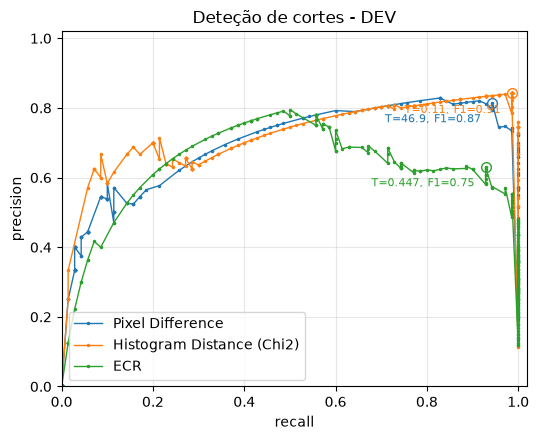

In [34]:
# Gerar o gráfico das curvas PR usando a função dada
plotting.plot_pr_curve(pr_curves_data, title="Deteção de cortes - DEV")
plt.show()

#### Combinação de sinais
O histograma falha em cortes entre planos de cores parecidas, e o ECR e a diferença de píxeis reagem a movimento e *flashes*. Por isso testamos um detetor combinado: os candidatos são os picos do melhor sinal (acima do seu limiar) e só são aceites se outro sinal também estiver acima do seu limiar no mesmo frame. Os dois limiares são escolhidos em conjunto, numa grelha no DEV.

In [35]:
best_signal = max(best_results, key=lambda s: best_results[s][3])
print(f"Sinal principal: {best_signal} (F1 sozinho = {best_results[best_signal][3]:.3f})\n")

combo_results = {}
for confirm_name in signal_names:
    if confirm_name == best_signal:
        continue
    max_main = best_results[best_signal][0] * 1.5      # com confirmação, o limiar principal pode baixar
    max_conf = max(np.max(dev_data[v]["signals"][confirm_name]) for v in dev_data)

    best = (0.0, 0.0, 0.0, 0.0, -1.0, 0)      # (t1, t2, p, r, f1, flash-FA)
    for t1 in np.linspace(0, max_main, 30):
        for t2 in np.linspace(0, max_conf, 30):
            preds = {name: detect_cuts_combined(data["signals"][best_signal], t1, data["signals"][confirm_name], t2)
                     for name, data in dev_data.items()}
            p, r, f1, fa = evaluate_cuts(preds)
            if f1 > best[4]:
                best = (t1, t2, p, r, f1, fa)
    combo_results[confirm_name] = best

print(f"{'Confirmação':<28} | {'T principal':<11} | {'T confirm.':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'Flash-FA':<8}")
print("-" * 103)
for confirm_name, (t1, t2, p, r, f1, fa) in combo_results.items():
    print(f"{confirm_name:<28} | {t1:<11.4f} | {t2:<10.4f} | {p:<10.3f} | {r:<10.3f} | {f1:<10.3f} | {fa}/{num_flashes}")

Sinal principal: Histogram Distance (Chi2) (F1 sozinho = 0.908)

Confirmação                  | T principal | T confirm. | Precision  | Recall     | F1-Score   | Flash-FA
-------------------------------------------------------------------------------------------------------
Pixel Difference             | 0.0400      | 33.3024    | 0.843      | 1.000      | 0.915      | 12/12
ECR                          | 0.0914      | 0.3793     | 0.852      | 0.986      | 0.914      | 12/12


#### Configuração escolhida
A configuração com melhor $F_1$ no DEV (sinal sozinho ou combinação) é usada em `tp1.py`, nas constantes do início do ficheiro.

In [36]:
tp1_names = {"Pixel Difference": "pixel", "Histogram Distance (Chi2)": "histogram", "ECR": "ecr"}
best_combo = max(combo_results, key=lambda c: combo_results[c][4])

if combo_results[best_combo][4] > best_results[best_signal][3]:
    t1, t2 = combo_results[best_combo][:2]
    print(f'CUT_SIGNAL = "{tp1_names[best_signal]}"')
    print(f"CUT_THRESHOLD = {t1:.4f}")
    print(f'CONFIRM_SIGNAL = "{tp1_names[best_combo]}"')
    print(f"CONFIRM_THRESHOLD = {t2:.4f}")
else:
    print(f'CUT_SIGNAL = "{tp1_names[best_signal]}"')
    print(f"CUT_THRESHOLD = {best_results[best_signal][0]:.4f}")
    print("CONFIRM_SIGNAL = None")

CUT_SIGNAL = "histogram"
CUT_THRESHOLD = 0.0400
CONFIRM_SIGNAL = "pixel"
CONFIRM_THRESHOLD = 33.3024


#### Discussão
- **O histograma é o sinal isolado mais fiável** ($F_1$ = 0.908): dentro dos *shots* fica praticamente a zero, porque um histograma ignora a posição das cores e é pouco afetado pelo movimento. Falha sobretudo em cortes entre planos de cores parecidas.
- **O ECR é o mais sensível ao movimento** ($F_1$ = 0.751, precisão 0.631): com a câmara em movimento muitas arestas deslocam-se mais do que a dilatação tolera, o que gera vários picos de 0.2–0.3 dentro dos *shots* (visível no gráfico dos sinais).
- **A diferença de píxeis** fica a meio ($F_1$ = 0.874): reage a cortes mas também a qualquer variação global de intensidade.
- **Combinar sinais ajuda**: exigir que o histograma e a diferença de píxeis estejam ambos acima do limiar dá recall 1.000 e $F_1$ = 0.915. A confirmação com o ECR dá um resultado quase igual (0.914), o que indica que o ganho vem de exigir dois sinais e não de um sinal em particular.
- **Os *flashes* enganam todos os sinais** (12/12 com o detetor escolhido): um *flash* muda bruscamente a cor, a intensidade e as arestas da imagem, por isso nenhum limiar o separa de um corte. Quase todos os falsos positivos que restam vêm de *flashes*, e é isso que a verificação da Parte 2 vai atacar.

## 3. Part 2 - False alarms

Na Parte 1 o detetor encontrou todos os cortes do DEV, mas os 12 *flashes* deram todos falso alarme. Um *flash*, tal como o movimento rápido da câmara ou um objeto a passar à frente, muda muito a imagem mas acontece **dentro do mesmo shot**: o conteúdo antes e depois é a mesma cena. É isso que usamos para verificar cada corte candidato.

### Task 4 - Verificação com *features* locais

Para cada corte candidato $t$ (os cortes da Parte 1):

1. Comparamos as frames $t-g$ e $t+g$, com $g = 4$. Não usamos $t-1$ e $t$ porque um *flash* pode durar até 3 frames; com $g=4$ nenhuma das duas frames é do *flash*. Se $t$ for um corte real, $t-g$ é do *shot* antigo e $t+g$ do novo.
2. Detetamos *keypoints* SIFT nas duas frames e fazemos o *matching* dos descritores com `BFMatcher` e `knnMatch(k=2)`, ficando só com os *matches* que passam o **ratio test de Lowe** com `ratio = 0.7` (o valor usado no Lab 3): um *match* só é aceite se o vizinho mais próximo for claramente melhor que o segundo.
3. Opcionalmente, contamos só os **inliers do RANSAC** de uma homografia (`cv2.findHomography`), como no `filter_matches_RANSAC` do Lab 3. Os *inliers* são os *matches* que concordam com uma única transformação geométrica entre as duas frames, por isso *matches* soltos por acaso não contam.
4. Se o número de *matches* for **pelo menos** `MIN_MATCHES`, as duas frames mostram a mesma cena e o candidato é **rejeitado**; caso contrário fica como corte.

Usamos o `BFMatcher` em vez do FLANN do Lab 3 porque o FLANN usa árvores aleatórias e o número de *matches* pode variar ligeiramente entre execuções; com poucas dezenas de candidatos por vídeo, a procura exaustiva é rápida e dá sempre o mesmo resultado. Pela mesma razão fixamos a semente do RANSAC.

As funções estão em `tp1.py`: `sift_matches`, `ransac_inliers`, `count_matches`, `candidate_matches` e `verify_cuts`.

In [37]:
import tp1
from tp1 import sift_matches, ransac_inliers, candidate_matches

# nomes dos sinais no tp1.py -> nomes usados neste notebook
nome = {"pixel": "Pixel Difference", "histogram": "Histogram Distance (Chi2)", "ECR": "ECR", "ecr": "ECR"}

# Cortes candidatos: o detetor final da Parte 1 (constantes do tp1.py)
candidates = {}
for name, data in dev_data.items():
    sig = data["signals"][nome[tp1.CUT_SIGNAL]]
    conf = data["signals"][nome[tp1.CONFIRM_SIGNAL]]
    candidates[name] = detect_cuts_combined(sig, tp1.CUT_THRESHOLD, conf, tp1.CONFIRM_THRESHOLD)

p, r, f1, fa = evaluate_cuts(candidates)
print(f"Candidatos no DEV: {sum(len(c) for c in candidates.values())}")
print(f"Parte 1 (sem verificação): P={p:.3f}  R={r:.3f}  F1={f1:.3f}  flash-FA={fa}/{num_flashes}")

Candidatos no DEV: 83
Parte 1 (sem verificação): P=0.843  R=1.000  F1=0.915  flash-FA=12/12


In [38]:
# Número de matches de cada candidato, sem e com RANSAC (calculado uma vez, depois só se muda o limiar)
match_counts = {"matches (ratio test)": {}, "inliers RANSAC": {}}
t0 = time.time()
for name, data in dev_data.items():
    match_counts["matches (ratio test)"][name] = candidate_matches(data["frames"], candidates[name], use_ransac=False)
    match_counts["inliers RANSAC"][name] = candidate_matches(data["frames"], candidates[name], use_ransac=True)
print(f"SIFT nos candidatos: {time.time() - t0:.1f} s")


def is_real_cut(t, gt):
    # o candidato está a menos de 2 frames de um corte real (a mesma tolerância do match_cuts)
    return any(abs(t - trans["start"]) <= metrics.TOLERANCE for trans in gt["transitions"])


# Quantos matches têm os cortes reais e os falsos alarmes?
print(f"\n{'Contagem':<22} | {'Tipo':<14} | {'N':<4} | {'Mín':<5} | {'Média':<7} | {'Máx':<5}")
print("-" * 70)
for mode, counts in match_counts.items():
    real, fake = [], []
    for name, data in dev_data.items():
        for t, n in zip(candidates[name], counts[name]):
            (real if is_real_cut(t, data["gt"]) else fake).append(n)
    for label, vals in [("cortes reais", real), ("falsos alarmes", fake)]:
        print(f"{mode:<22} | {label:<14} | {len(vals):<4} | {min(vals):<5} | {np.mean(vals):<7.1f} | {max(vals):<5}")

SIFT nos candidatos: 3.7 s

Contagem               | Tipo           | N    | Mín   | Média   | Máx  
----------------------------------------------------------------------
matches (ratio test)   | cortes reais   | 70   | 0     | 1.5     | 8    
matches (ratio test)   | falsos alarmes | 13   | 2     | 160.8   | 408  
inliers RANSAC         | cortes reais   | 70   | 0     | 0.2     | 5    
inliers RANSAC         | falsos alarmes | 13   | 0     | 155.7   | 402  


#### Escolha do número mínimo de *matches*

Para cada forma de contar (*matches* simples ou *inliers* do RANSAC), variamos `MIN_MATCHES` de 1 a 150 e avaliamos no DEV os cortes que sobram. Quando vários valores dão o mesmo $F_1$ máximo, escolhemos o do meio desse intervalo, para ficar com margem para os dois lados.

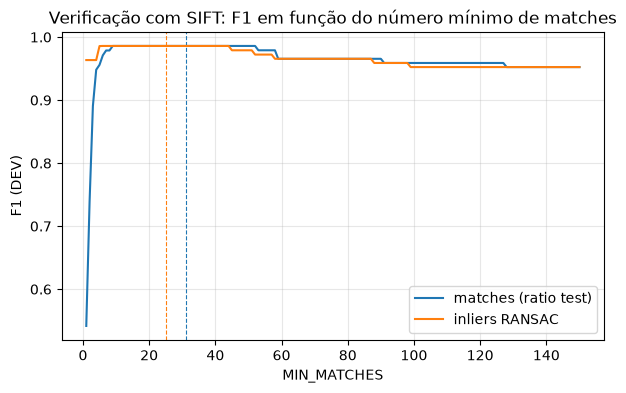

matches (ratio test)  : melhor MIN_MATCHES = 31  ->  P=0.972  R=1.000  F1=0.986  flash-FA=1/12
inliers RANSAC        : melhor MIN_MATCHES = 25  ->  P=0.972  R=1.000  F1=0.986  flash-FA=1/12


In [39]:
min_values = list(range(1, 151))
sweep = {}
for mode, counts in match_counts.items():
    rows = []
    for m in min_values:
        kept = {name: [t for t, n in zip(candidates[name], counts[name]) if n < m] for name in dev_data}
        p, r, f1, fa = evaluate_cuts(kept)
        rows.append((m, p, r, f1, fa))
    sweep[mode] = rows

# melhor F1 de cada modo (meio do intervalo de valores com F1 máximo)
best_verify = {}
for mode, rows in sweep.items():
    best_f1 = max(row[3] for row in rows)
    best_rows = [row for row in rows if row[3] == best_f1]
    best_verify[mode] = best_rows[len(best_rows) // 2]

fig, ax = plt.subplots(figsize=(7, 4))
for mode, rows in sweep.items():
    ax.plot([row[0] for row in rows], [row[3] for row in rows], label=mode)
    m = best_verify[mode][0]
    ax.axvline(m, ls="--", lw=0.8, color=ax.lines[-1].get_color())
ax.set_xlabel("MIN_MATCHES")
ax.set_ylabel("F1 (DEV)")
ax.set_title("Verificação com SIFT: F1 em função do número mínimo de matches")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

for mode, (m, p, r, f1, fa) in best_verify.items():
    print(f"{mode:<22}: melhor MIN_MATCHES = {m}  ->  P={p:.3f}  R={r:.3f}  F1={f1:.3f}  flash-FA={fa}/{num_flashes}")

#### Deliverable — Tabela com e sem verificação

In [40]:
p, r, f1, fa = evaluate_cuts(candidates)
print(f"{'Método':<44} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10} | {'Flash-FA':<8}")
print("-" * 94)
print(f"{'Parte 1 (sem verificação)':<44} | {p:<10.3f} | {r:<10.3f} | {f1:<10.3f} | {fa}/{num_flashes}")
for mode, (m, p, r, f1, fa) in best_verify.items():
    label = f"+ verificação, {mode} >= {m}"
    print(f"{label:<44} | {p:<10.3f} | {r:<10.3f} | {f1:<10.3f} | {fa}/{num_flashes}")

Método                                       | Precision  | Recall     | F1-Score   | Flash-FA
----------------------------------------------------------------------------------------------
Parte 1 (sem verificação)                    | 0.843      | 1.000      | 0.915      | 12/12
+ verificação, matches (ratio test) >= 31    | 0.972      | 1.000      | 0.986      | 1/12
+ verificação, inliers RANSAC >= 25          | 0.972      | 1.000      | 0.986      | 1/12


In [41]:
# Modo escolhido e o que mudou: falsos alarmes que ficaram e cortes reais que foram rejeitados
best_mode = max(best_verify, key=lambda mode: best_verify[mode][3])
best_min = best_verify[best_mode][0]
print(f"Modo escolhido: {best_mode}, MIN_MATCHES = {best_min}\n")

remaining_fa = []    # falsos alarmes que a verificacao nao conseguiu remover
for name, data in dev_data.items():
    counts = match_counts[best_mode][name]
    for t, n in zip(candidates[name], counts):
        real = is_real_cut(t, data["gt"])
        kept = n < best_min
        if real and not kept:
            print(f"{name} frame {t}: corte REAL rejeitado ({n} matches)")
        if not real and kept:
            print(f"{name} frame {t}: falso alarme que ficou ({n} matches)")
            remaining_fa.append((name, t))

Modo escolhido: matches (ratio test), MIN_MATCHES = 31

dev_01 frame 3342: falso alarme que ficou (6 matches)
dev_02 frame 1867: falso alarme que ficou (2 matches)


#### Deliverable — Exemplo de um falso alarme removido

À esquerda a frame $t-4$ e à direita a frame $t+4$ de um candidato que era um *flash*: a cena é a mesma e há muitos *matches*, por isso o candidato foi rejeitado. Por baixo, para comparação, um corte real que foi mantido: quase não há *matches* entre os dois lados.

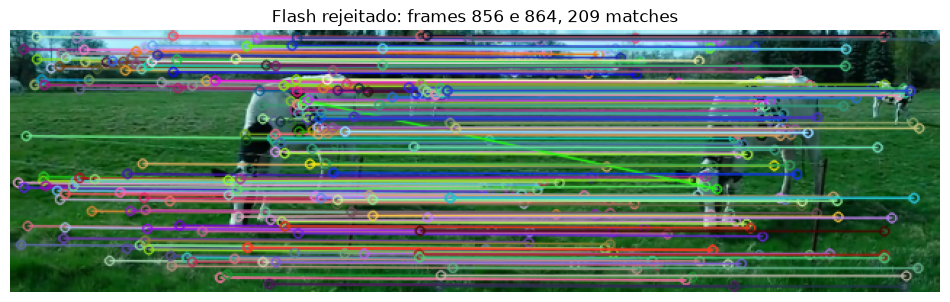

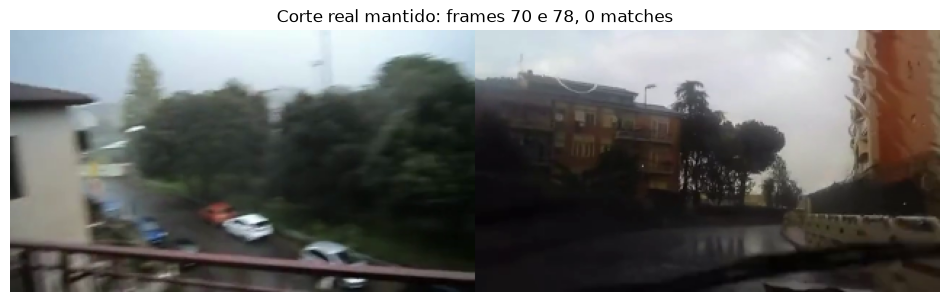

In [42]:
def draw_candidate(frames, t, title):
    f1, f2 = frames[max(0, t - tp1.GAP)], frames[min(len(frames) - 1, t + tp1.GAP)]
    kp1, kp2, good = sift_matches(f1, f2)
    if best_mode == "inliers RANSAC":
        good = ransac_inliers(kp1, kp2, good)
    img = cv2.drawMatches(f1, kp1, f2, kp2, good, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    plt.figure(figsize=(12, 3.6))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"{title}: frames {t - tp1.GAP} e {t + tp1.GAP}, {len(good)} matches")
    plt.axis("off")
    plt.show()

data = dev_data["dev_01"]
counts = match_counts[best_mode]["dev_01"]
flash_frames = [f["start"] for f in data["gt"]["distractors"]]

# primeiro candidato rejeitado que era um flash, e primeiro corte real mantido
removed = [t for t, n in zip(candidates["dev_01"], counts)
           if n >= best_min and any(abs(t - f) <= 3 for f in flash_frames)]
kept_real = [t for t, n in zip(candidates["dev_01"], counts) if n < best_min and is_real_cut(t, data["gt"])]

if removed:
    draw_candidate(data["frames"], removed[0], "Flash rejeitado")
if kept_real:
    draw_candidate(data["frames"], kept_real[0], "Corte real mantido")

#### Falsos alarmes que a verificação não removeu

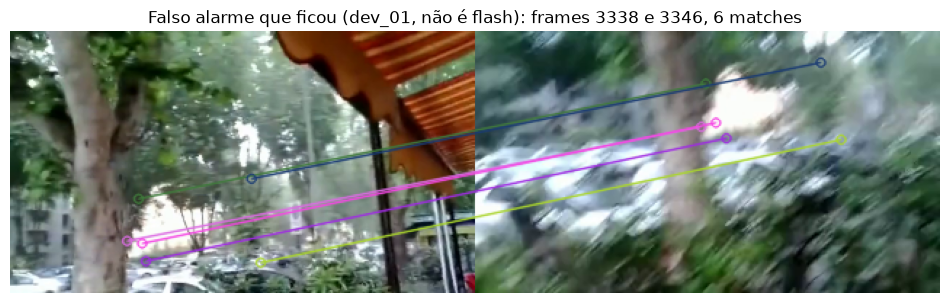

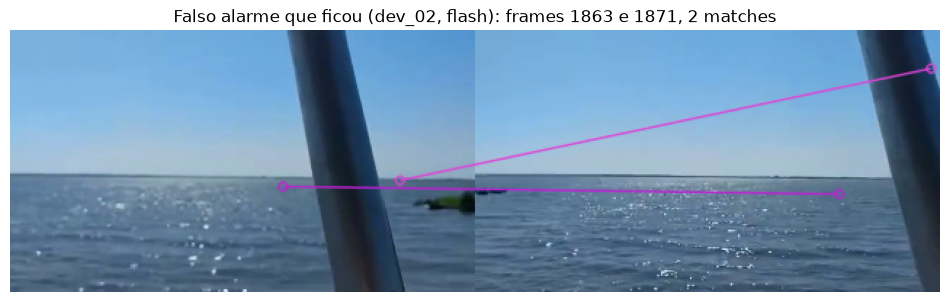

In [43]:
for name, t in remaining_fa:
    flashes = [f for f in dev_data[name]["gt"]["distractors"] if abs(f["start"] - t) <= 3]
    tipo = "flash" if flashes else "não é flash"
    draw_candidate(dev_data[name]["frames"], t, f"Falso alarme que ficou ({name}, {tipo})")

#### Configuração escolhida
O modo e o limiar com melhor $F_1$ no DEV são usados em `tp1.py` (constantes `USE_RANSAC` e `MIN_MATCHES`).

In [44]:
print(f"USE_RANSAC = {best_mode == 'inliers RANSAC'}")
print(f"MIN_MATCHES = {best_min}")

USE_RANSAC = False
MIN_MATCHES = 31


#### Discussão
- **A verificação elimina quase todos os falsos alarmes**: o $F_1$ no DEV sobe de 0.915 para 0.986 e só 1 dos 12 *flashes* continua a disparar o detetor. O recall mantém-se em 1.000, ou seja, nenhum corte real foi rejeitado.
- **A separação é muito clara**: os cortes reais têm no máximo 8 *matches* (média 1.5), enquanto os falsos alarmes têm em média 160. Por isso o $F_1$ é praticamente constante para `MIN_MATCHES` entre ~10 e ~45, e o valor escolhido (31) tem margem para os dois lados. Mesmo os cortes entre *takes* do mesmo local (como o do elétrico) têm poucos *matches*: entre $t-4$ e $t+4$ as pessoas e a câmara estão noutras posições.
- **O RANSAC não muda o resultado**: com *inliers* os cortes reais ficam ainda mais perto de zero (máximo 5), mas o $F_1$ é o mesmo. Ficámos com a versão mais simples, sem RANSAC.
- **Os dois falsos alarmes que ficam** mostram os limites do SIFT. No `dev_01` (frame 3342) a câmara faz um movimento brusco e a frame $t+4$ fica desfocada, por isso quase não há *keypoints* (6 *matches*). No `dev_02` (frame 1867, um *flash*) a cena é mar e céu: o céu não tem textura e os reflexos da água mudam a cada frame, por isso só há 2 *matches*, apesar de ser a mesma cena. O SIFT precisa de textura estável e estes frames quase não a têm.

## 4. Part 3 - Recurring scenes

Os editores voltam muitas vezes a uma cena que já apareceu antes. Nesta parte agrupamos os *shots* que vêm da mesma cena. Para separar esta parte das anteriores, usamos os *shots* do *ground truth* (campo `shots` do JSON) e não os cortes que detetámos, por isso os erros das Partes 1 e 2 não afetam estes resultados.

### Task 5 - Representar cada shot por keyframes

As semelhanças são sempre calculadas entre **keyframes** (frames escolhidas de cada *shot*), nunca entre *shots* inteiros. Comparamos duas estratégias:

1. **Um keyframe** (`middle_keyframe`): a frame do meio do *shot*. É a mais simples, mas um só frame pode não representar bem um *shot* em que a câmara se move ou em que passa alguém à frente.
2. **Vários keyframes** (`sample_keyframes`): `N_KEYFRAMES = 5` frames espalhadas de forma uniforme pelo *shot*. Ignoramos 10% no início e no fim (`KEYFRAME_MARGIN`): perto dos cortes a câmara está muitas vezes a começar ou a acabar um movimento e as frames ficam desfocadas. Em *shots* curtos os índices repetidos são removidos, por isso podem sair menos de 5.

Primeiro vemos como são os *shots* do DEV, para perceber se 5 keyframes fazem sentido.

In [45]:
from tp1 import middle_keyframe, sample_keyframes, shot_keyframes, combine_keyframe_sims

print(f"{'Vídeo':<8} | {'Shots':<5} | {'Cenas':<5} | {'Cenas repetidas':<15} | {'Duração mín':<11} | {'Mediana':<7} | {'Máx':<5}")
print("-" * 76)
for name, data in dev_data.items():
    shots = data["gt"]["shots"]
    lengths = [s["end"] - s["start"] + 1 for s in shots]
    scene_count = {}
    for s in shots:
        scene_count[s["scene"]] = scene_count.get(s["scene"], 0) + 1
    repeated = sum(1 for c in scene_count.values() if c > 1)
    print(f"{name:<8} | {len(shots):<5} | {len(scene_count):<5} | {repeated:<15} | "
          f"{min(lengths):<11} | {int(np.median(lengths)):<7} | {max(lengths):<5}")

Vídeo    | Shots | Cenas | Cenas repetidas | Duração mín | Mediana | Máx  
----------------------------------------------------------------------------
dev_01   | 37    | 28    | 8               | 29          | 96      | 195  
dev_02   | 35    | 19    | 11              | 30          | 98      | 221  


In [46]:
# Keyframes de cada shot com as duas estratégias
keyframes = {}
for name, data in dev_data.items():
    keyframes[name] = {"middle": shot_keyframes(data["gt"]["shots"], mode="middle"),
                       "multi": shot_keyframes(data["gt"]["shots"], mode="multi")}

# Verificação: quantos keyframes caem em cima de um flash? (só para análise, o método não usa os flashes)
for mode in ["middle", "multi"]:
    total, on_flash = 0, 0
    for name, data in dev_data.items():
        flash_frames = set()
        for f in data["gt"]["distractors"]:
            flash_frames.update(range(f["start"], f["end"] + 1))
        for kfs in keyframes[name][mode]:
            total += len(kfs)
            on_flash += sum(1 for t in kfs if t in flash_frames)
    print(f"{mode:<6}: {total} keyframes no DEV, {on_flash} em cima de um flash")

middle: 72 keyframes no DEV, 2 em cima de um flash
multi : 360 keyframes no DEV, 2 em cima de um flash


Os *shots* têm pelo menos 29 frames (mediana ≈ 97), por isso 5 keyframes ficam afastados ≈ 6 frames ou mais e nunca se repetem. A maioria das cenas aparece num só *shot* (no `dev_01`, 37 *shots* vêm de 28 cenas e só 8 se repetem), o que quer dizer que muitos *shots* devem ficar sozinhos: juntar *shots* por engano vai custar muita precisão.

Com um só keyframe, 2 dos 72 *shots* do DEV ficam representados por uma frame com *flash* (quase branca), o que estraga a semelhança desses *shots* com todos os outros. Com 5 keyframes, esses *shots* têm mais 4 keyframes normais, por isso o *flash* pesa muito menos. É uma vantagem de usar vários keyframes, que vamos confirmar com os resultados da Task 6.

#### Exemplo: keyframes de shots da mesma cena

Escolhemos em `dev_01` a cena com mais *shots* (S05, um barco) e mostramos os 5 keyframes de cada um; o keyframe mais perto do meio do *shot*, que é o da estratégia 1, tem a moldura vermelha. Neste caso os três *shots* vêm do mesmo *take* com a câmara quase parada, por isso são muito parecidos entre si e também ao longo de cada *shot*: é um caso fácil, que qualquer das estratégias deve agrupar. Os casos difíceis são *shots* da mesma cena em que a câmara se moveu ou a luz mudou, e *shots* de cenas diferentes que se parecem; esses aparecem na análise da Task 7.

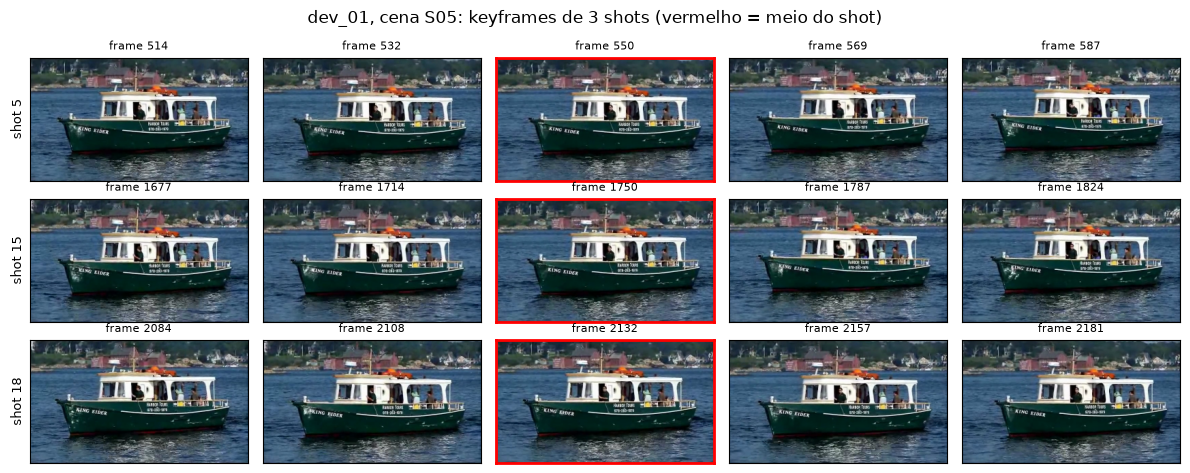

In [47]:
data = dev_data["dev_01"]
shots = data["gt"]["shots"]

# cena com mais shots em dev_01
scene_shots = {}
for i, s in enumerate(shots):
    scene_shots.setdefault(s["scene"], []).append(i)
scene = max(scene_shots, key=lambda sc: len(scene_shots[sc]))
example = scene_shots[scene][:4]

n_cols = max(len(keyframes["dev_01"]["multi"][i]) for i in example)
fig, axs = plt.subplots(len(example), n_cols, figsize=(2.4 * n_cols, 1.6 * len(example)), squeeze=False)
for row, i in enumerate(example):
    kfs = keyframes["dev_01"]["multi"][i]
    middle = middle_keyframe(shots[i])[0]
    for col in range(n_cols):
        ax = axs[row][col]
        ax.set_xticks([])
        ax.set_yticks([])
        if col >= len(kfs):
            ax.axis("off")
            continue
        ax.imshow(cv2.cvtColor(data["frames"][kfs[col]], cv2.COLOR_BGR2RGB))
        ax.set_title(f"frame {kfs[col]}", fontsize=8)
        # o keyframe mais perto do meio tem moldura vermelha
        if kfs[col] == min(kfs, key=lambda t: abs(t - middle)):
            for spine in ax.spines.values():
                spine.set_edgecolor("red")
                spine.set_linewidth(2)
    axs[row][0].set_ylabel(f"shot {shots[i]['id']}", fontsize=9)
fig.suptitle(f"dev_01, cena {scene}: keyframes de {len(example)} shots (vermelho = meio do shot)")
plt.tight_layout()
plt.show()

#### Como juntar as semelhanças de vários keyframes

Com vários keyframes, dois *shots* $A$ e $B$ dão uma matriz de semelhanças $s_{ij}$ entre o keyframe $i$ de $A$ e o keyframe $j$ de $B$ (calculadas na Task 6). Para ter um só número por par de *shots*, testamos três formas (`combine_keyframe_sims`):

- **`max` (melhor par):** $\max_{i,j} s_{ij}$. Basta que um momento de $A$ seja parecido com um momento de $B$. Ajuda quando a câmara se move durante o *shot*, mas um só par parecido por acaso pode juntar cenas diferentes.
- **`mean` (média):** a média de todos os pares. É mais estável, mas penaliza *shots* em que só uma parte é parecida.
- **`best_mean` (melhor par de cada keyframe):** para cada keyframe de $A$ procura o mais parecido em $B$, e vice-versa, e faz a média. Fica entre as duas: cada keyframe precisa de ter um "parceiro", mas não têm de ser todos parecidos com todos.

Exemplo com 3 keyframes em $A$ e 2 em $B$:

In [48]:
example_sims = np.array([[0.2, 0.9],
                         [0.1, 0.3],
                         [0.4, 0.5]])
for how in ["max", "mean", "best_mean"]:
    print(f"{how:<9}: {combine_keyframe_sims(example_sims, how):.3f}")

max      : 0.900
mean     : 0.400
best_mean: 0.608


O `max` só vê o par 0.9; a `mean` é puxada para baixo pelos pares fracos (0.1, 0.2); o `best_mean` faz a média de $(0.9 + 0.3 + 0.5)/3$ e de $(0.4 + 0.9)/2$, ou seja, $(0.567 + 0.65)/2 = 0.608$.

A escolha da estratégia (1 ou vários keyframes) e da forma de combinar é feita **na Task 6, com os resultados no DEV**, porque depende da semelhança usada (cor ou SIFT).

## 5. Results (development and test)

## 6. Analysis and failure cases

## 7. Conclusion and self-evaluation

## 8. Extras

## 9. Use of AI tools